# Gas Exported Flows Prediction and GPR Impact Analysis

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load, Preprocess Data and time series characteristics

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Load monthly gas flow data
df_flows = pd.read_excel('/content/drive/MyDrive/monthlygaz.xlsx', header=0)
df_flows.columns = df_flows.iloc[0]
df_flows = df_flows[1:].copy()

# Rename columns to ensure consistency
df_flows = df_flows.rename(columns={
    'Date': 'Date',
    'Exported_flows': 'Exported_flows',
    'Unit_flow': 'Unit_flow',
    'Prices': 'Prices',
    'Unit_price': 'Unit_price'
})

# Ensure 'Date' is datetime and set as index
df_flows['Date'] = pd.to_datetime(df_flows['Date'])
df_flows.set_index('Date', inplace=True)

# Resample df_flows to month-end
df_flows_resampled = df_flows.resample('ME').last()

# Load Geopolitical Risk (GPR) dataset
df_gpr = pd.read_excel('/content/drive/MyDrive/GPR.xlsx')

# Ensure 'Date' is parsed correctly as yearly format and set as index
df_gpr['Date'] = pd.to_datetime(df_gpr['Date'], format='%Y')
df_gpr.set_index('Date', inplace=True)

# Resample df_gpr to monthly and forward-fill missing values
df_gpr_monthly = df_gpr.resample('ME').ffill()

# --- Code from d5BMTdJ6Y4ql (with adjustments for merged context) ---

# Construct the 'df' DataFrame from the available dataframes.
# 1. Select and rename columns from df_flows_resampled
df_gas_data = df_flows_resampled[['Exported_flows', 'Prices']].copy()
df_gas_data.columns = ['Gas_Flow', 'Gas_Price']
# Convert to numeric, coercing errors to NaN
df_gas_data['Gas_Flow'] = pd.to_numeric(df_gas_data['Gas_Flow'], errors='coerce')
df_gas_data['Gas_Price'] = pd.to_numeric(df_gas_data['Gas_Price'], errors='coerce')

# 2. Select and rename a GPR column from df_gpr_monthly
# Assuming 'GPR OF ALGERIA' is the intended geopolitical index
df_gpr_data = df_gpr_monthly[['GPR OF ALGERIA']].copy()
df_gpr_data = df_gpr_monthly[['GPR OF SPAIN']].copy()
df_gpr_data.columns = ['Geopolitical_Index']
# Convert to numeric
df_gpr_data['Geopolitical_Index'] = pd.to_numeric(df_gpr_data['Geopolitical_Index'], errors='coerce')

# 3. Merge these two dataframes into 'df'
# Use an outer merge to ensure all dates from both are considered
df = pd.merge(df_gas_data, df_gpr_data, left_index=True, right_index=True, how='outer')

# Fill any NaNs that resulted from the merge by interpolation.
# 'limit_direction='both'' ensures filling at the beginning or end if needed.
df['Geopolitical_Index'] = df['Geopolitical_Index'].interpolate(method='linear', limit_direction='both')
df['Gas_Flow'] = df['Gas_Flow'].interpolate(method='linear', limit_direction='both')
df['Gas_Price'] = df['Gas_Price'].interpolate(method='linear', limit_direction='both')

# Trim the dataframe to the common date range or the range where all data is available,
# to avoid issues with predictions on future dates where GPR is missing.
# df_gpr_monthly goes up to 2023-01-31.
df = df.loc[df.index <= df_gpr_monthly.index.max()]

# 2. Smoothing geopolitical index data (Interpolation) if jumps are sharp
# This line is redundant after the previous interpolation block, but kept for consistency if it was intended to be run again.
df['Geopolitical_Index'] = df['Geopolitical_Index'].interpolate(method='linear')

# 3. Stationarity check function (ADF Test)
def check_stationarity(series, name):
    result = adfuller(series)
    print(f'--- ADF Test for: {name} ---')
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    if result[1] <= 0.05:
        print("(Stationary)")
    else:
        print("(Non-Stationary) -> it is preferable to take differences or rely on cautious scaling")

check_stationarity(df['Gas_Flow'], 'Gas Flow')
check_stationarity(df['Gas_Price'], 'Gas Price')
check_stationarity(df['Geopolitical_Index'], 'Geopolitical Index')

print("Merged and processed data, performed stationarity checks.")

--- ADF Test for: Gas Flow ---
ADF Statistic: -3.933893884923251
p-value: 0.0017990932410208433
(Stationary)
--- ADF Test for: Gas Price ---
ADF Statistic: -5.553416958729083
p-value: 1.6007373084303489e-06
(Stationary)
--- ADF Test for: Geopolitical Index ---
ADF Statistic: -1.8939969314781862
p-value: 0.3348903922296871
(Non-Stationary) -> it is preferable to take differences or rely on cautious scaling
Merged and processed data, performed stationarity checks.


### Time Series Decomposition for Gas Flow, Gas Price, GPR of Algeria, and GPR of Spain

We will now decompose each of the relevant time series into their observed, trend, seasonal, and residual components to better understand their underlying patterns. The `seasonal_decompose` function from `statsmodels.tsa.seasonal` will be used with an additive model and a period of 12 (for monthly data).

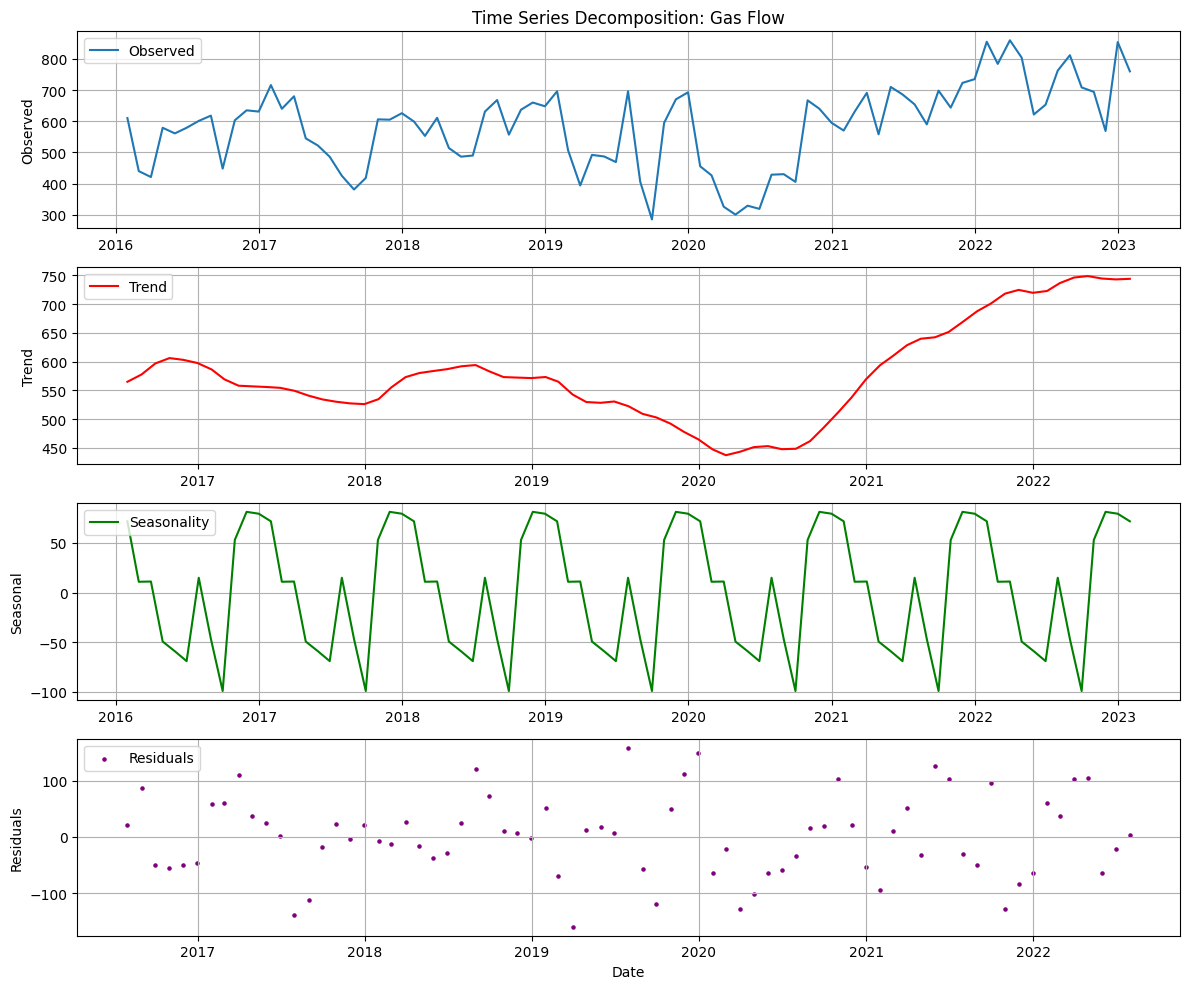

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose Gas Flow
plt.figure(figsize=(12, 10))
result_gas_flow = seasonal_decompose(df['Gas_Flow'], model='additive', period=12)

plt.subplot(4, 1, 1)
plt.plot(result_gas_flow.observed, label='Observed')
plt.title('Time Series Decomposition: Gas Flow')
plt.ylabel('Observed')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(result_gas_flow.trend, label='Trend', color='red')
plt.ylabel('Trend')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(result_gas_flow.seasonal, label='Seasonality', color='green')
plt.ylabel('Seasonal')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.scatter(result_gas_flow.resid.index, result_gas_flow.resid, label='Residuals', color='purple', s=5)
plt.ylabel('Residuals')
plt.xlabel('Date')
plt.legend(loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

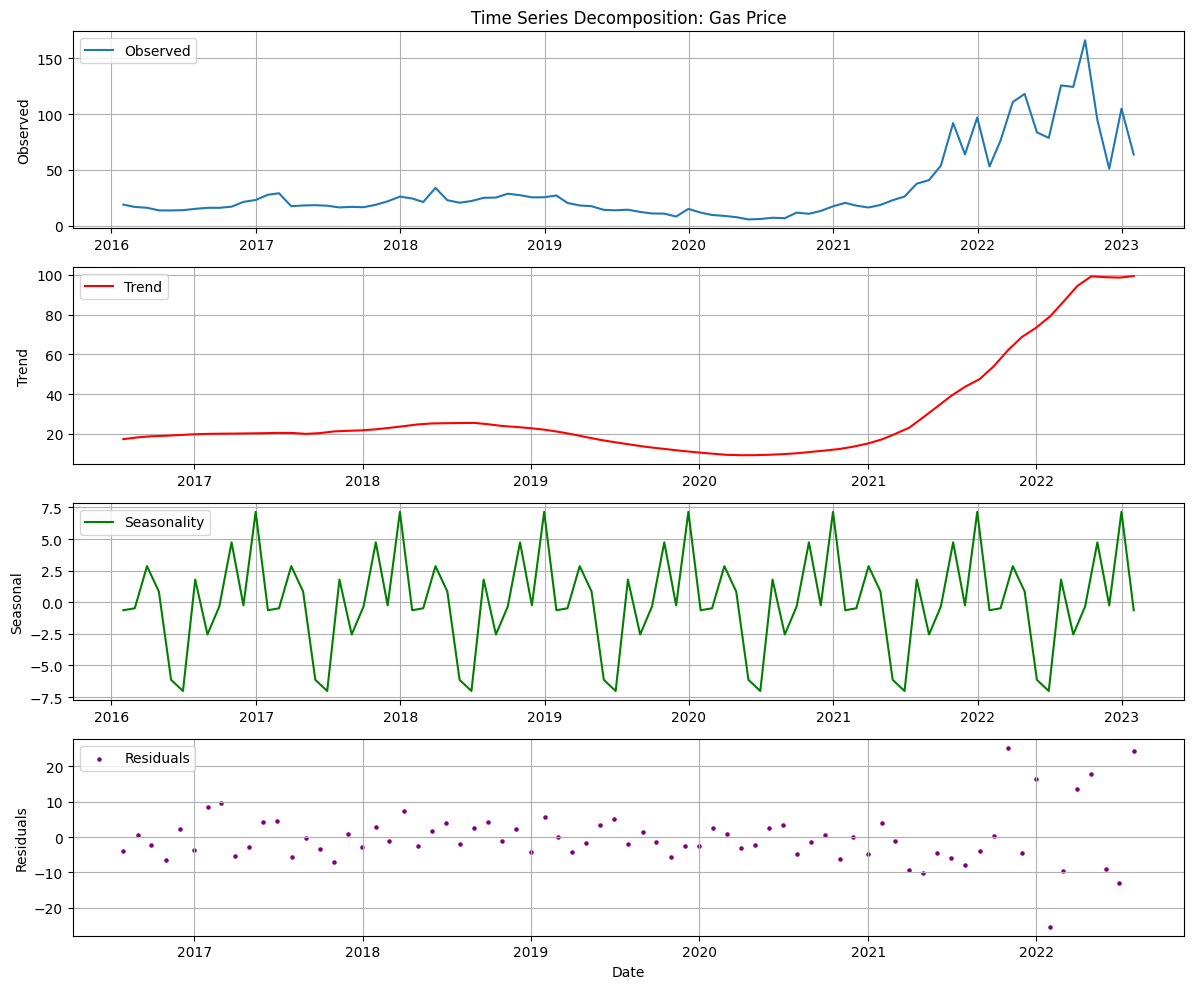

In [4]:
# Decompose Gas Price
plt.figure(figsize=(12, 10))
result_gas_price = seasonal_decompose(df['Gas_Price'], model='additive', period=12)

plt.subplot(4, 1, 1)
plt.plot(result_gas_price.observed, label='Observed')
plt.title('Time Series Decomposition: Gas Price')
plt.ylabel('Observed')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(result_gas_price.trend, label='Trend', color='red')
plt.ylabel('Trend')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(result_gas_price.seasonal, label='Seasonality', color='green')
plt.ylabel('Seasonal')
plt.legend(loc='upper left')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.scatter(result_gas_price.resid.index, result_gas_price.resid, label='Residuals', color='purple', s=5)
plt.ylabel('Residuals')
plt.xlabel('Date')
plt.legend(loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

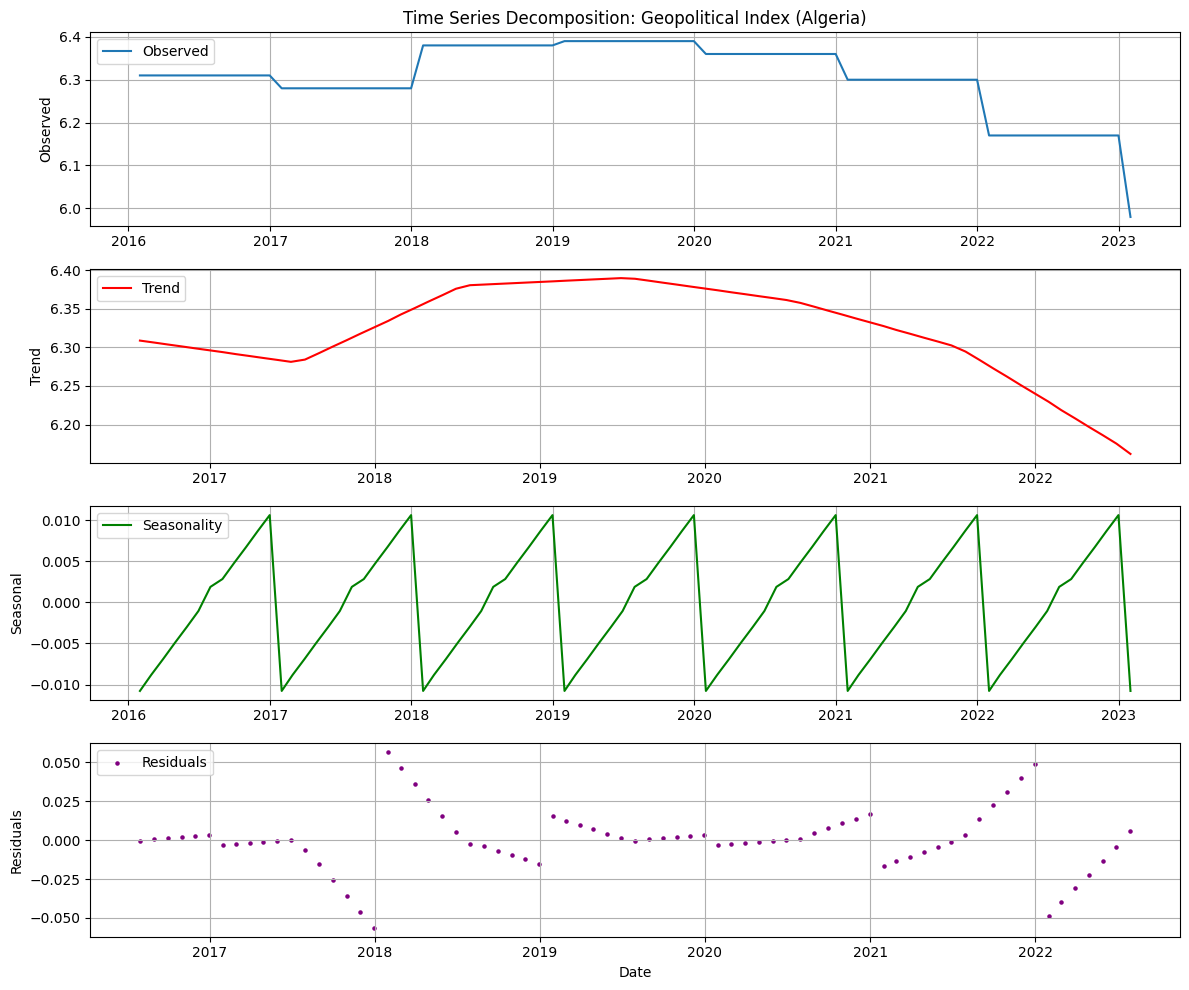

In [5]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose Geopolitical Index (Algeria)
plt.figure(figsize=(12, 10))

# Ensure the series has at least 2 full periods (24 data points for monthly with period=12)
# If not enough data, decomposition might fail or be less reliable.
series_gpr_algeria = df_gpr_monthly['GPR OF ALGERIA'].dropna()

if len(series_gpr_algeria) >= 24:
    result_gpr_index = seasonal_decompose(series_gpr_algeria, model='additive', period=12)

    plt.subplot(4, 1, 1)
    plt.plot(result_gpr_index.observed, label='Observed')
    plt.title('Time Series Decomposition: Geopolitical Index (Algeria)')
    plt.ylabel('Observed')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 2)
    plt.plot(result_gpr_index.trend, label='Trend', color='red')
    plt.ylabel('Trend')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 3)
    plt.plot(result_gpr_index.seasonal, label='Seasonality', color='green')
    plt.ylabel('Seasonal')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 4)
    plt.scatter(result_gpr_index.resid.index, result_gpr_index.resid, label='Residuals', color='purple', s=5)
    plt.ylabel('Residuals')
    plt.xlabel('Date')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough data points ({len(series_gpr_algeria)}) in 'GPR OF ALGERIA' for reliable seasonal decomposition (requires at least 24 for period=12).")

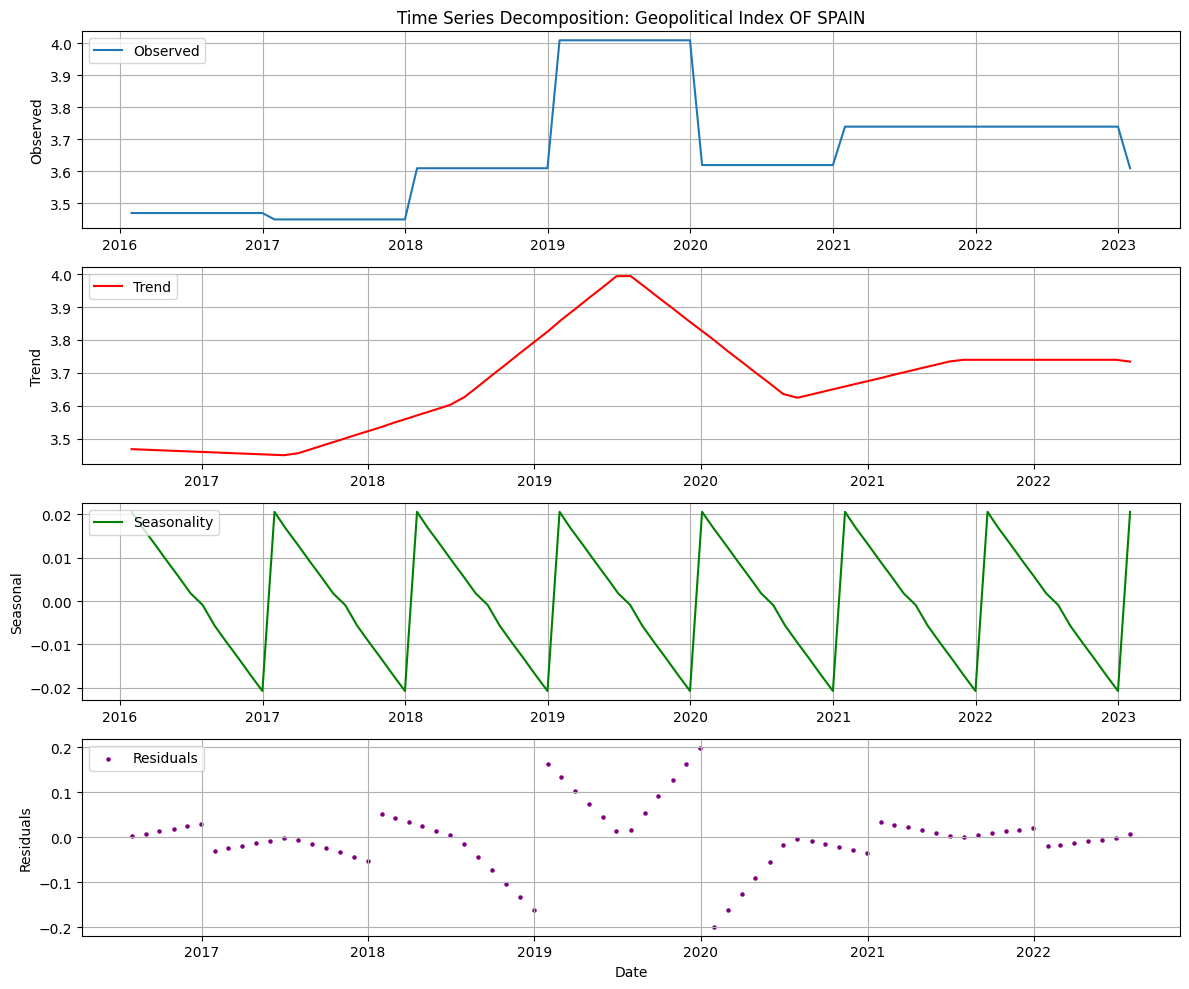

In [6]:
# Decompose GPR OF SPAIN
plt.figure(figsize=(12, 10))
# Ensure df_gpr_monthly has 'GPR OF SPAIN' and its index is suitable for time series decomposition
# The ffill operation already handled NaNs, but a final check for any remaining NaNs is good practice.
series_gpr_spain = df_gpr_monthly['GPR OF SPAIN'].dropna()

# Ensure the series has at least 2 full periods (24 data points for monthly with period=12)
# If not enough data, decomposition might fail or be less reliable.
if len(series_gpr_spain) >= 24:
    result_gpr_spain = seasonal_decompose(series_gpr_spain, model='additive', period=12)

    plt.subplot(4, 1, 1)
    plt.plot(result_gpr_spain.observed, label='Observed')
    plt.title('Time Series Decomposition: Geopolitical Index OF SPAIN')
    plt.ylabel('Observed')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 2)
    plt.plot(result_gpr_spain.trend, label='Trend', color='red')
    plt.ylabel('Trend')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 3)
    plt.plot(result_gpr_spain.seasonal, label='Seasonality', color='green')
    plt.ylabel('Seasonal')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.subplot(4, 1, 4)
    plt.scatter(result_gpr_spain.resid.index, result_gpr_spain.resid, label='Residuals', color='purple', s=5)
    plt.ylabel('Residuals')
    plt.xlabel('Date')
    plt.legend(loc='upper left')
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough data points ({len(series_gpr_spain)}) in 'GPR OF SPAIN' for reliable seasonal decomposition (requires at least 24 for period=12).")

In [7]:
import matplotlib as mpl
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import tensorflow as tf

mpl.rcParams['figure.figsize'] = (15, 15)
mpl.rcParams['axes.grid'] = False

## 2. Data Exploration and Feature Engineering

In [8]:
print(df_flows.head)
print(df_gpr.head)

<bound method NDFrame.head of 0          Exported_flows Unit_flow Prices Unit_price
Date                                                 
2016-01-05        610.232      Mm˄3     19    EUR/MWh
2016-02-01            440      Mm˄3  16.93    EUR/MWh
2016-03-01            421      Mm˄3  16.21    EUR/MWh
2016-04-01            579      Mm˄3  13.85    EUR/MWh
2016-05-01            561      Mm˄3  13.80    EUR/MWh
...                   ...       ...    ...        ...
2025-08-01        826.828      Mm˄3   34.6    EUR/MWh
2025-09-01        665.082      Mm˄3  31.55    EUR/MWh
2025-10-01        665.082      Mm˄3  30.61    EUR/MWh
2025-11-01        877.073      Mm˄3  30.28    EUR/MWh
2025-12-01          836.4      Mm˄3  28.08    EUR/MWh

[120 rows x 4 columns]>
<bound method NDFrame.head of             GPR OF ALGERIA  GPR OF SPAIN
Date                                    
2016-01-01            6.31          3.47
2017-01-01            6.28          3.45
2018-01-01            6.38          3.61
2019-01-

In [9]:
df_flows.rename(columns={'Unnamed: 0': 'Date'}, inplace=True)

## 3. Data Scaling and Timeseries Generation

In [10]:
# 1. Scaling Data and Separating Variables
scaler = MinMaxScaler()
# Delete the Date column and scale data between 0 and 1
data_scaled = scaler.fit_transform(df.drop('Date', axis=1) if 'Date' in df.columns else df)

# Define Features and Target
features = data_scaled[:, 1:]
target = data_scaled[:, 0]

# 2. Split data into training and testing while preserving chronological order
x_train, x_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=123,
    shuffle=False  # very important for time series
)

# Print dimensions for verification
print("Training features shape:", x_train.shape)
print("Testing features shape:", x_test.shape)

# 3. Timeseries Generator settings
win_length = 3      # Window length (e.g., 3 months)
batch_size = 32     # Batch size for training
num_features = 5    # Number of features used

# Create training and testing data generators
train_generator = TimeseriesGenerator(x_train, y_train, length=win_length, sampling_rate=1, batch_size=batch_size)
test_generator = TimeseriesGenerator(x_test, y_test, length=win_length, sampling_rate=1, batch_size=batch_size)

# 4. Preview the first batch from the training generator to see how the data looks
first_batch = train_generator[0]
x_batch, y_batch = first_batch

print("\n--- First Batch Preview ---")
print("Batch X shape (Samples, Time Steps, Features):", x_batch.shape)
print("Batch Y shape (Targets):", y_batch.shape)

Training features shape: (68, 2)
Testing features shape: (17, 2)

--- First Batch Preview ---
Batch X shape (Samples, Time Steps, Features): (32, 3, 2)
Batch Y shape (Targets): (32,)


In [11]:
df_flows_aligned = df_flows.copy()
df_flows_aligned = df_flows_aligned.reset_index() # Reset index to make 'Date' a column
df_flows_aligned['Date'] = df_flows_aligned['Date'].dt.to_period('M').dt.end_time.dt.normalize()
df_flows_aligned.set_index('Date', inplace=True)

df_merged = df_flows_aligned.merge(df_gpr_monthly, left_index=True, right_index=True, how='inner')

df_merged.reset_index(inplace=True)
df_merged.rename(columns={'index': 'Date'}, inplace=True)

df_input = df_merged[["Date", "Exported_flows", "Prices", "GPR OF ALGERIA", "GPR OF SPAIN"]].copy()
df_input['Gas_lag1'] = df_input['Exported_flows'].shift(1)
df_input['Gas_lag2'] = df_input['Exported_flows'].shift(2)


df_input.dropna(inplace=True)

df_input['Gas_lag1'] = pd.to_numeric(df_input['Gas_lag1'], errors='coerce')
df_input['Gas_lag2'] = pd.to_numeric(df_input['Gas_lag2'], errors='coerce')
display(df_input.head())

,Date,Exported_flows,Prices,GPR OF ALGERIA,GPR OF SPAIN,Gas_lag1,Gas_lag2
2,2016-03-31,421,16.21,6.31,3.47,440.0,610.232
3,2016-04-30,579,13.85,6.31,3.47,421.0,440.000
4,2016-05-31,561,13.80,6.31,3.47,579.0,421.000
5,2016-06-30,579,14.05,6.31,3.47,561.0,579.000
6,2016-07-31,601,15.22,6.31,3.47,579.0,561.000


In [12]:
df_input.describe()

,Date,GPR OF ALGERIA,GPR OF SPAIN,Gas_lag1,Gas_lag2
count,83,83.000000,83.000000,83.000000,83.000000
mean,2019-08-30 23:42:39.036144640,6.308916,3.666867,583.118855,580.181892
min,2016-03-31 00:00:00,5.980000,3.450000,285.000000,285.000000
25%,2017-12-15 12:00:00,6.280000,3.470000,486.678500,486.678500
50%,2019-08-31 00:00:00,6.310000,3.620000,603.000000,603.000000
75%,2021-05-15 12:00:00,6.380000,3.740000,669.104000,667.543000
max,2023-01-31 00:00:00,6.390000,4.010000,859.685000,859.685000
std,NaN,0.079756,0.176745,132.862077,129.451647


### 2.1 Outlier Analysis (Optional)

In [13]:
df_input[df_input["Exported_flows"] < df_input["Exported_flows"].quantile(0.90)]

,Date,Exported_flows,Prices,GPR OF ALGERIA,GPR OF SPAIN,Gas_lag1,Gas_lag2
2,2016-03-31,421,16.21,6.31,3.47,440.000,610.232
3,2016-04-30,579,13.85,6.31,3.47,421.000,440.000
4,2016-05-31,561,13.80,6.31,3.47,579.000,421.000
5,2016-06-30,579,14.05,6.31,3.47,561.000,579.000
6,2016-07-31,601,15.22,6.31,3.47,579.000,561.000
...,...,...,...,...,...,...,...
76,2022-05-31,621.649,83.65,6.17,3.74,804.018,859.685
77,2022-06-30,653.068,78.64,6.17,3.74,621.649,804.018
80,2022-09-30,708.491,165.95,6.17,3.74,811.819,762.449
81,2022-10-31,694.272,94.75,6.17,3.74,708.491,811.819


## 4. Define and Train LSTM Model

In [14]:
model = tf.keras.Sequential()

model.add(tf.keras.Input(shape=(win_length, num_features)))

model.add(tf.keras.layers.LSTM(128, return_sequences=True))
model.add(tf.keras.layers.LeakyReLU(negative_slope=0.5))

model.add(tf.keras.layers.LSTM(128, return_sequences=True))
model.add(tf.keras.layers.LeakyReLU(negative_slope=0.5))

model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.LSTM(64, return_sequences=False))

model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(1))


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 3, 128)         │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 3, 128)         │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,665 (975.25 KB)

 Trainable params: 249,665 (975.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                                    patience=2,
                                                    mode='min')
num_features = 2

model = tf.keras.Sequential()
model.add(tf.keras.Input(shape=(win_length, num_features)))
model.add(tf.keras.layers.LSTM(128, return_sequences=True))
model.add(tf.keras.layers.LeakyReLU(negative_slope=0.5))
model.add(tf.keras.layers.LSTM(128, return_sequences=True))
model.add(tf.keras.layers.LeakyReLU(negative_slope=0.5))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.LSTM(64, return_sequences=False))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(1))

model.compile(loss=tf.losses.MeanSquaredError(),
              optimizer=tf.optimizers.Adam(),
              metrics=[tf.metrics.MeanAbsoluteError()])

history = model.fit(train_generator, epochs=50,
                    validation_data=test_generator,
                    shuffle=False,
                    callbacks=[early_stopping])

Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 355ms/step - loss: 0.2448 - mean_absolute_error: 0.4536 - val_loss: 0.5973 - val_mean_absolute_error: 0.7578
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.2113 - mean_absolute_error: 0.4164 - val_loss: 0.5133 - val_mean_absolute_error: 0.7001
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1731 - mean_absolute_error: 0.3744 - val_loss: 0.4047 - val_mean_absolute_error: 0.6175
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1286 - mean_absolute_error: 0.3153 - val_loss: 0.2681 - val_mean_absolute_error: 0.4941
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0875 - mean_absolute_error: 0.2613 - val_loss: 0.1235 - val_mean_absolute_error: 0.3174
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0701 - mean_absolute_error: 0.2262 - val_loss: 0.0495 - val_mean_absolute_error: 0.1939
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0728 - mean_absolute_error: 0.2143 - val_loss: 0.0419 - va

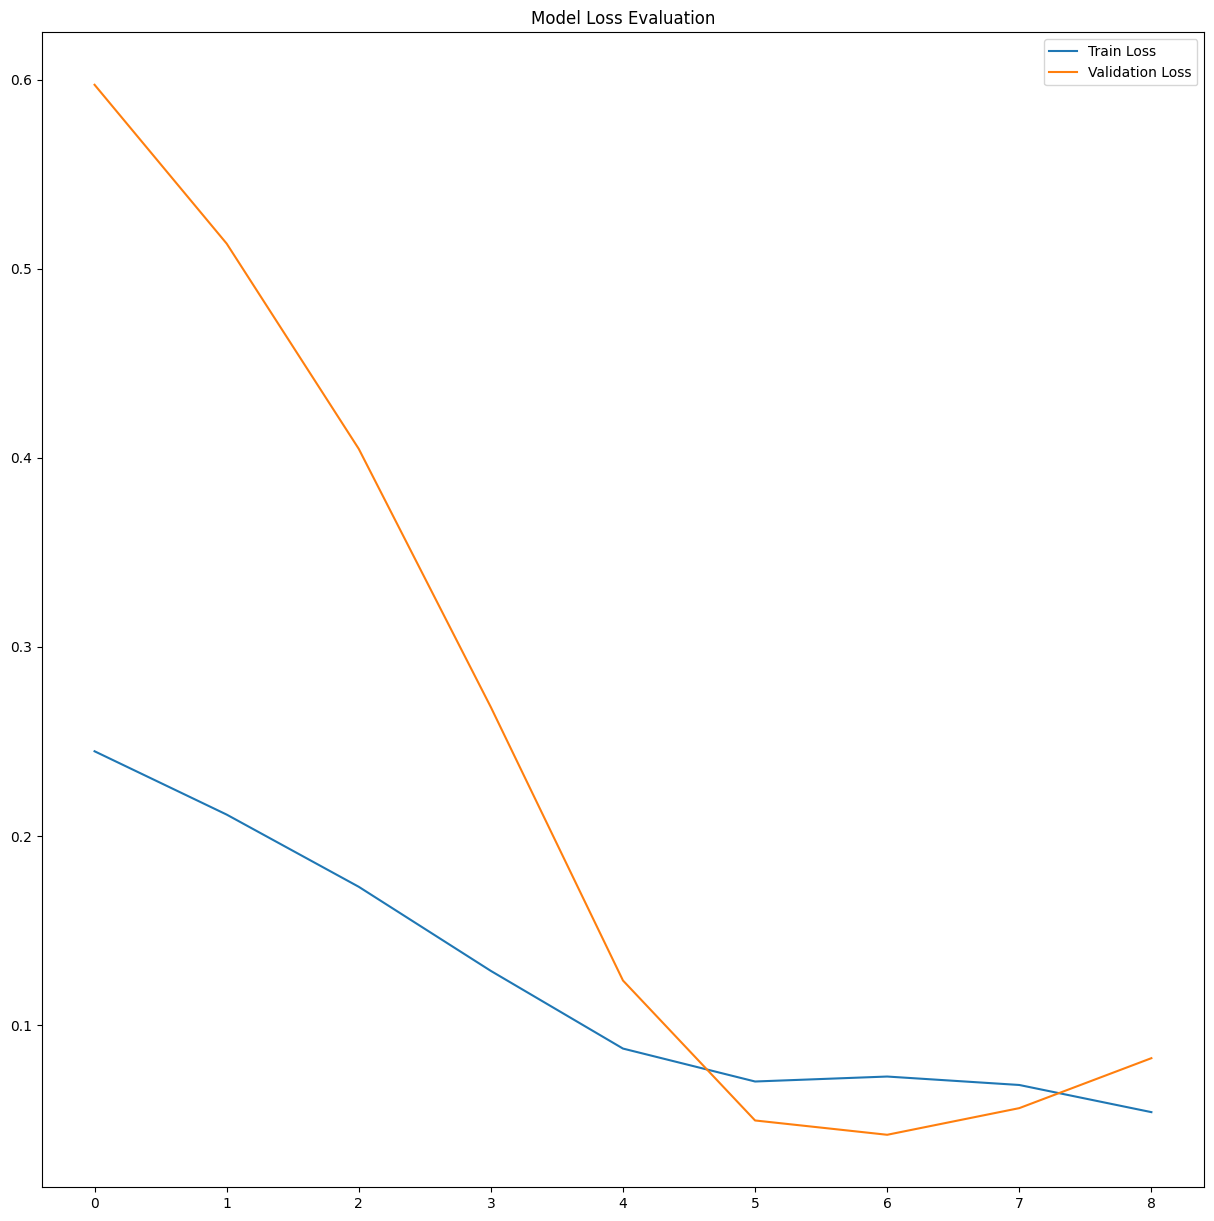

In [17]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss Evaluation')
plt.show()

## 5. Evaluate and Predict with LSTM Model

In [18]:
model.evaluate(test_generator, verbose=0)

[0.08246251195669174, 0.25358524918556213]

In [25]:
import numpy as np
mse = model.evaluate(train_generator, verbose=0)[0]
rmse = np.sqrt(mse)
mae = model.evaluate(train_generator, verbose=0)[1]
mse = model.evaluate(test_generator, verbose=0)[0]
rmse = np.sqrt(mse)
mae = model.evaluate(test_generator, verbose=0)[1]

print(f'Mean Squared Error (MSE) on train data: {mse:.4f}')
print(f'Root Mean Squared Error (RMSE) on train data: {rmse:.4f}')
print(f'Mean Absolute Error (MAE) on train data: {mae:.4f}')
print(f'Mean Squared Error (MSE) on test data: {mse:.4f}')
print(f'Root Mean Squared Error (RMSE) on test data: {rmse:.4f}')
print(f'Mean Absolute Error (MAE) on test data: {mae:.4f}')

Mean Squared Error (MSE) on train data: 0.0825
Root Mean Squared Error (RMSE) on train data: 0.2872
Mean Absolute Error (MAE) on train data: 0.2536
Mean Squared Error (MSE) on test data: 0.0825
Root Mean Squared Error (RMSE) on test data: 0.2872
Mean Absolute Error (MAE) on test data: 0.2536


### 5.1 Inverse Transform and Visualization

In [20]:

# 1. Generate predictions using the model and the test time generator
predictions = model.predict(test_generator)
print(f"Number of predictions generated: {predictions.shape[0]}")

# 2. Prepare the array for Inverse Transform
# We concatenate the predictions with x_test features after skipping the first window length (win_length)
# to get 6 columns matching what the scaler was trained on
df_pred_array = np.concatenate([predictions, x_test[win_length:]], axis=1)

# Convert the merged array to a DataFrame
df_pred = pd.DataFrame(df_pred_array)
print("\n--- First 5 rows of merged data (scaled between 0 and 1) ---")
display(df_pred.head())

# 3. Inverse transform and retrieve original true values
rev_trans = scaler.inverse_transform(df_pred)

print(f"\nArray dimensions after retrieving original values: {rev_trans.shape}")
print("Preview of retrieved true values:\n", rev_trans[:5]) # Print only the first 5 rows for brevity

actual_predictions = rev_trans[:, 0]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step
Number of predictions generated: 14

--- First 5 rows of merged data (scaled between 0 and 1) ---


,0,1,2
0,0.541748,0.569172,0.517857
1,0.557204,0.295917,0.517857
2,0.547353,0.440192,0.517857
3,0.555044,0.655513,0.517857
4,0.541397,0.700587,0.517857



Array dimensions after retrieving original values: (14, 3)
Preview of retrieved true values:
 [[596.33437356  96.94         3.74      ]
 [605.21705943  53.17         3.74      ]
 [599.55540435  76.28         3.74      ]
 [603.97542423 110.77         3.74      ]
 [596.13299491 117.99         3.74      ]]


<Axes: title={'center': 'Actual vs Predicted Gas Flow'}, xlabel='Date'>

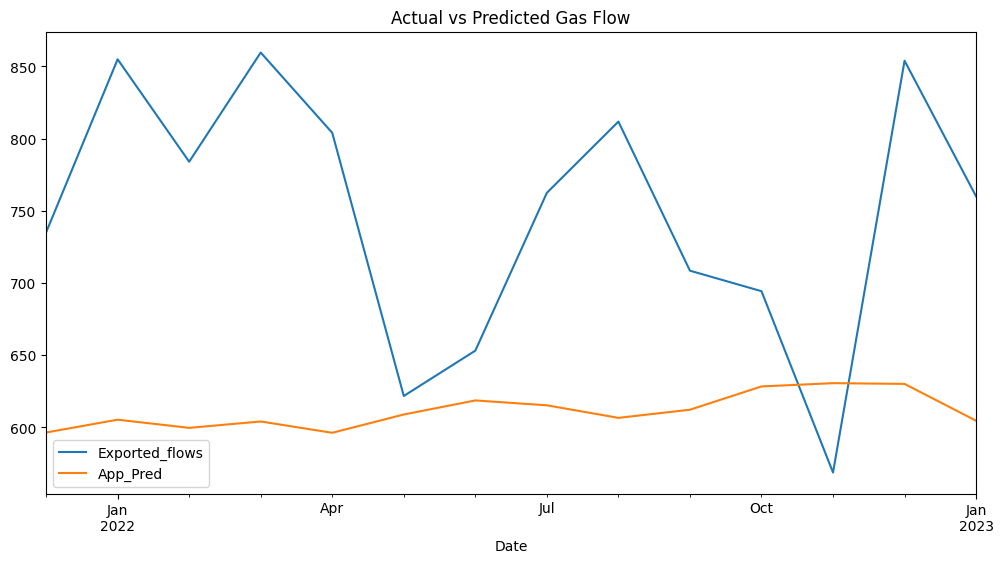

In [21]:
# Reconstruct df_final to include actual and predicted values for plotting.
# The 'Exported_flows' in `df` corresponds to 'Gas_Flow' from the original dataset.
# `x_train` has 68 samples, `win_length` is 3.
# The predictions correspond to target values from df.iloc[len(x_train) + win_length:]
start_idx_for_actuals = len(x_train) + win_length

# Create a DataFrame for actual values using the dates corresponding to the predictions
# We use `df` as it contains the original 'Gas_Flow' values (which are 'Exported_flows')
# and has a consistent date index covering the prediction period.
df_final = df.iloc[start_idx_for_actuals:].copy()
df_final.rename(columns={'Gas_Flow': 'Exported_flows'}, inplace=True)

# Add the inverse-transformed predictions as a new column 'App_Pred'
df_final['App_Pred'] = actual_predictions

# Now plot the actual vs. predicted gas flow
df_final[['Exported_flows','App_Pred']].plot(
    title="Actual vs Predicted Gas Flow",
    figsize=(12,6)
)

## . 6. Implement and Evaluate Linear Regression Model:

Linear Regression Mean Squared Error (MSE) on test data: 0.7938
Linear Regression Root Mean Squared Error (RMSE) on test data: 0.8910
Linear Regression Mean Absolute Error (MAE) on test data: 0.7757


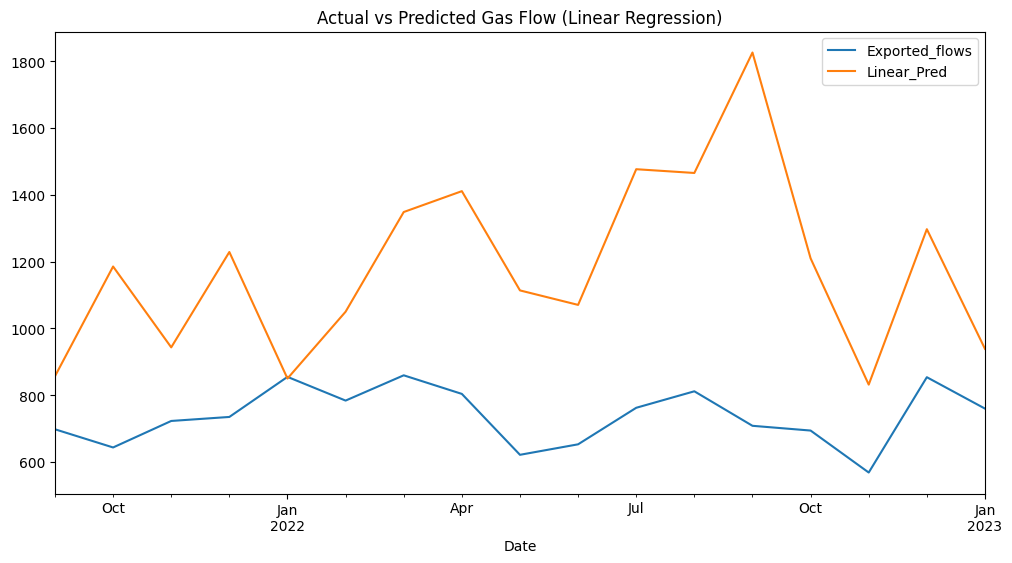

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Initialize and train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

# Make predictions on the test set
linear_predictions_scaled = linear_model.predict(x_test)

# Reshape predictions to match the original target shape if necessary
linear_predictions_scaled = linear_predictions_scaled.reshape(-1, 1)

df_linear_pred_array = np.concatenate([linear_predictions_scaled, x_test], axis=1)

# Inverse transform the predictions
rev_trans_linear = scaler.inverse_transform(df_linear_pred_array)

# Extract the inverse transformed 'Exported_flows' predictions (which is the first column after inverse transform)
linear_predictions = rev_trans_linear[:, 0]

# Evaluate the Linear Regression model on the scaled data
mse_lr = mean_squared_error(y_test, linear_predictions_scaled)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, linear_predictions_scaled)

print(f'Linear Regression Mean Squared Error (MSE) on test data: {mse_lr:.4f}')
print(f'Linear Regression Root Mean Squared Error (RMSE) on test data: {rmse_lr:.4f}')
print(f'Linear Regression Mean Absolute Error (MAE) on test data: {mae_lr:.4f}')

# Align actual values with linear regression predictions for plotting
# The test set (y_test) corresponds to the last len(y_test) rows of the original 'df' DataFrame.
# len(x_train) is 68 and len(y_test) is 17. So, we take df.iloc[68:85].
df_linear_comparison = df.iloc[len(x_train):len(x_train) + len(y_test)].copy()
df_linear_comparison.rename(columns={'Gas_Flow': 'Exported_flows'}, inplace=True)
df_linear_comparison.loc[:, 'Linear_Pred'] = linear_predictions

# Plotting Actual vs. Linear Regression Predicted Gas Flow
df_linear_comparison[['Exported_flows', 'Linear_Pred']].plot(
    title="Actual vs Predicted Gas Flow (Linear Regression)",
    figsize=(12, 6)
)
plt.show()

7. Visualize GPR Impact on Exported Flows:

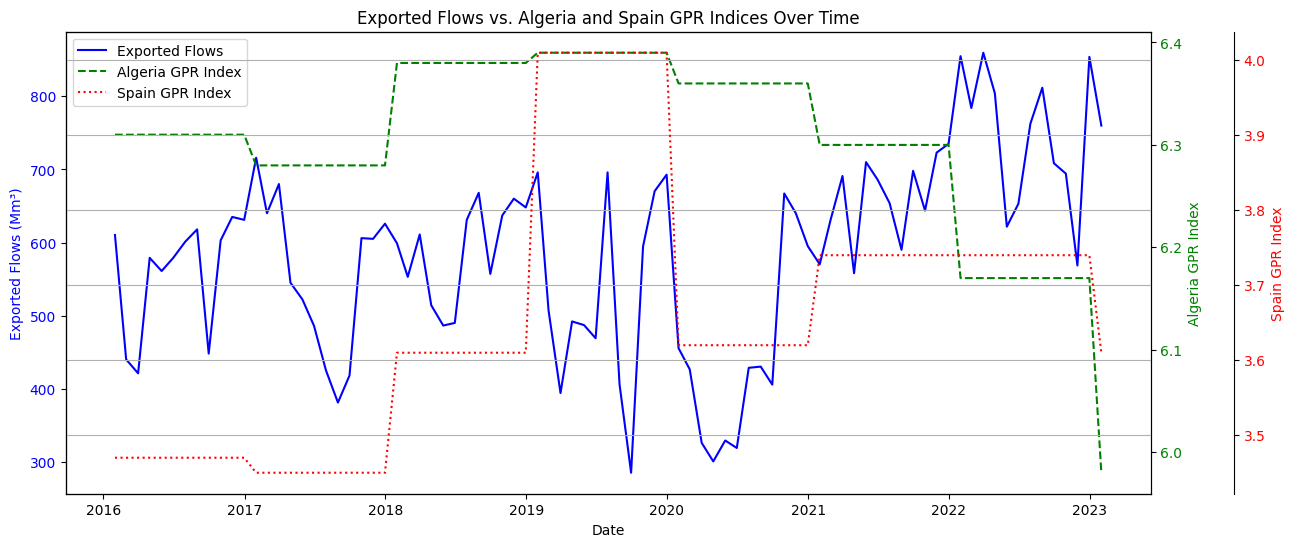

In [23]:
fig, ax1 = plt.subplots(figsize=(14,6))

# ---  ---
ax1.plot(df_merged['Date'], df_merged['Exported_flows'], color='blue', label='Exported Flows')
ax1.set_xlabel('Date')
ax1.set_ylabel('Exported Flows (Mm³)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# GPRALGERIA---
ax2 = ax1.twinx()
ax2.plot(df_merged['Date'], df_merged['GPR OF ALGERIA'], color='green', linestyle='--', label='Algeria GPR Index')
ax2.set_ylabel('Algeria GPR Index', color='green')
ax2.tick_params(axis='y', labelcolor='green')

# GPR SPAIN ---
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 60))
ax3.plot(df_merged['Date'], df_merged['GPR OF SPAIN'], color='red', linestyle=':', label='Spain GPR Index')
ax3.set_ylabel('Spain GPR Index', color='red')
ax3.tick_params(axis='y', labelcolor='red')

# --- --
plt.title('Exported Flows vs. Algeria and Spain GPR Indices Over Time')

# ---legend ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
lines_3, labels_3 = ax3.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2 + lines_3,
           labels_1 + labels_2 + labels_3,
           loc='upper left')

plt.grid(True)
plt.show()

## 8. Compare LSTM and Linear Regression Models


--- Model Performance Comparison ---
LSTM Model:  MSE=0.0825, RMSE=0.2872, MAE=0.2536
Linear Regression Model: MSE=0.7938, RMSE=0.8910, MAE=0.7757


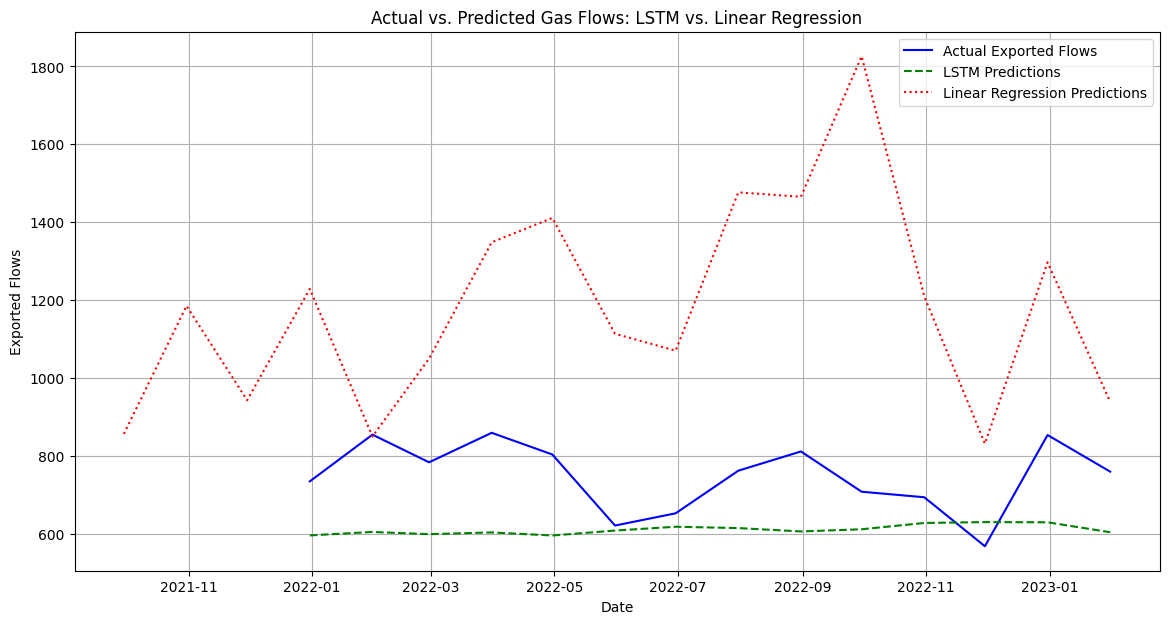

In [24]:
# Summarize performance metrics for both models
print("\n--- Model Performance Comparison ---")
print(f"LSTM Model:  MSE={model.evaluate(test_generator, verbose=0)[0]:.4f}, RMSE={np.sqrt(model.evaluate(test_generator, verbose=0)[0]):.4f}, MAE={model.evaluate(test_generator, verbose=0)[1]:.4f}")
print(f"Linear Regression Model: MSE={mse_lr:.4f}, RMSE={rmse_lr:.4f}, MAE={mae_lr:.4f}")

# Further comparison can be done by plotting both predictions against actuals on the same graph
plt.figure(figsize=(14, 7))
plt.plot(df_final.index, df_final['Exported_flows'], label='Actual Exported Flows', color='blue')
plt.plot(df_final.index, df_final['App_Pred'], label='LSTM Predictions', color='green', linestyle='--')
plt.plot(df_linear_comparison.index, df_linear_comparison['Linear_Pred'], label='Linear Regression Predictions', color='red', linestyle=':')
plt.title('Actual vs. Predicted Gas Flows: LSTM vs. Linear Regression')
plt.xlabel('Date')
plt.ylabel('Exported Flows')
plt.legend()
plt.grid(True)
plt.show()